In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

# Load the dataset

df = pd.read_csv (r"C:\Users\User\Documents\Iron Hack\Week5\Day 2\archive\amz_uk_price_prediction_dataset.csv")



In [6]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [7]:
# Create a crosstab between product_category and isBestSeller
crosstab = pd.crosstab(df['category'], df['isBestSeller'])

# Calculate the proportion of best-sellers for each category
crosstab['best_seller_proportion'] = crosstab[True] / (crosstab[True] + crosstab[False])

# Sort the categories based on the proportion in descending order
sorted_crosstab = crosstab.sort_values(by='best_seller_proportion', ascending=False)

# Display the sorted crosstab
print(sorted_crosstab)

isBestSeller                      False  True  best_seller_proportion
category                                                             
Grocery                            9008   556                0.058135
Smart Home Security & Lighting       98     6                0.057692
Health & Personal Care             9017   552                0.057686
Mobile Phone Accessories            248    11                0.042471
Power & Hand Tools                 8353   306                0.035339
...                                 ...   ...                     ...
CD, Disc & Tape Players            8798     0                0.000000
General Music-Making Accessories    259     0                0.000000
Snowboard Boots                    1449     0                0.000000
Boxes & Organisers                  911     0                0.000000
eBook Readers & Accessories         246     0                0.000000

[296 rows x 3 columns]


In [9]:
import pandas as pd
import scipy.stats as stats
import numpy as np

# Create a contingency table
contingency_table = pd.crosstab(df['category'], df['isBestSeller'])

# Chi-square test of independence
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)

print(f"Chi-square Statistic: {chi2}")
print(f"p-value: {p}")

# Compute Cramér's V
n = contingency_table.sum().sum()  # Total number of observations
phi2 = chi2 / n
r, k = contingency_table.shape
cramers_v = np.sqrt(phi2 / min(r - 1, k - 1))

print(f"Cramér's V: {cramers_v}")

Chi-square Statistic: 36540.20270061387
p-value: 0.0
Cramér's V: 0.1222829439760564


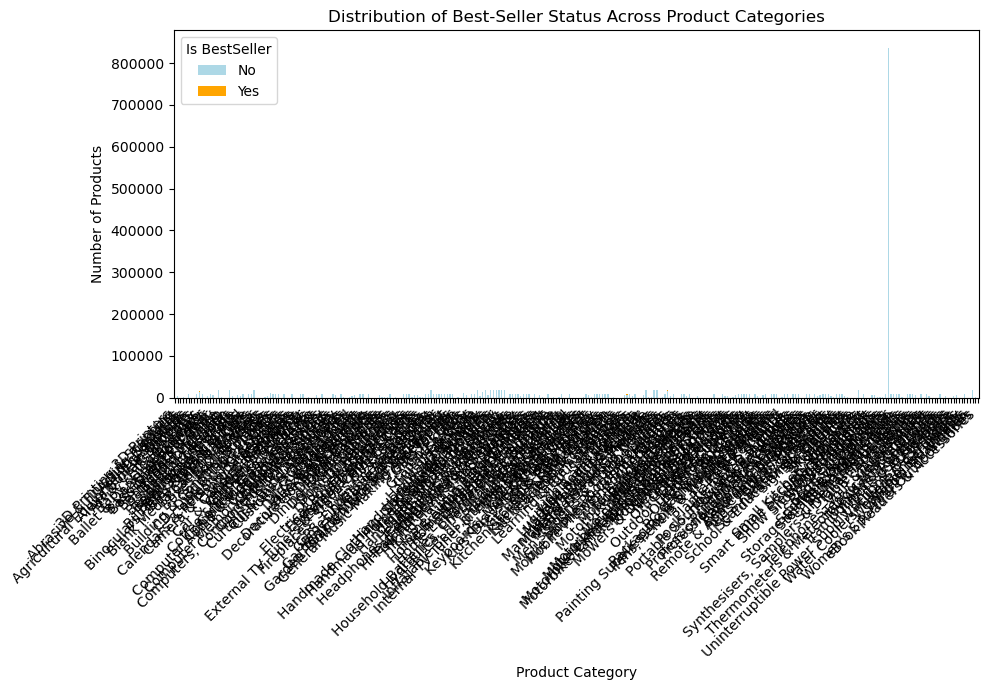

In [10]:
import pandas as pd
import matplotlib.pyplot as plt



# Plotting
contingency_table.plot(kind='bar', stacked=True, figsize=(10, 7), color=['lightblue', 'orange'])

# Adding titles and labels
plt.title('Distribution of Best-Seller Status Across Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Number of Products')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Is BestSeller', labels=['No', 'Yes'])
plt.tight_layout()

# Show the plot
plt.show()

In [11]:

# Calculate Q1 (25th percentile) and Q3 (75th percentile)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Define lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the dataframe to exclude outliers
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

# Display the updated DataFrame
print(df_no_outliers.describe())

                uid         stars       reviews         price  \
count  2.115963e+06  2.115963e+06  2.115963e+06  2.115963e+06   
mean   1.374141e+06  2.275402e+00  5.205211e+02  2.340827e+01   
std    8.169684e+05  2.193863e+00  6.233481e+03  2.051335e+01   
min    1.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00   
25%    6.589495e+05  0.000000e+00  0.000000e+00  9.130000e+00   
50%    1.347315e+06  3.400000e+00  1.000000e+00  1.599000e+01   
75%    2.067576e+06  4.400000e+00  7.500000e+01  2.999000e+01   
max    2.828593e+06  5.000000e+00  1.356658e+06  9.999000e+01   

       boughtInLastMonth  
count       2.115963e+06  
mean        2.970697e+01  
std         2.579316e+02  
min         0.000000e+00  
25%         0.000000e+00  
50%         0.000000e+00  
75%         0.000000e+00  
max         5.000000e+04  


C:\Users\User\AppData\Local\Temp\ipykernel_26116\1818740153.py:19: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(x='category', y='price', data=df_top_categories, scale='width')


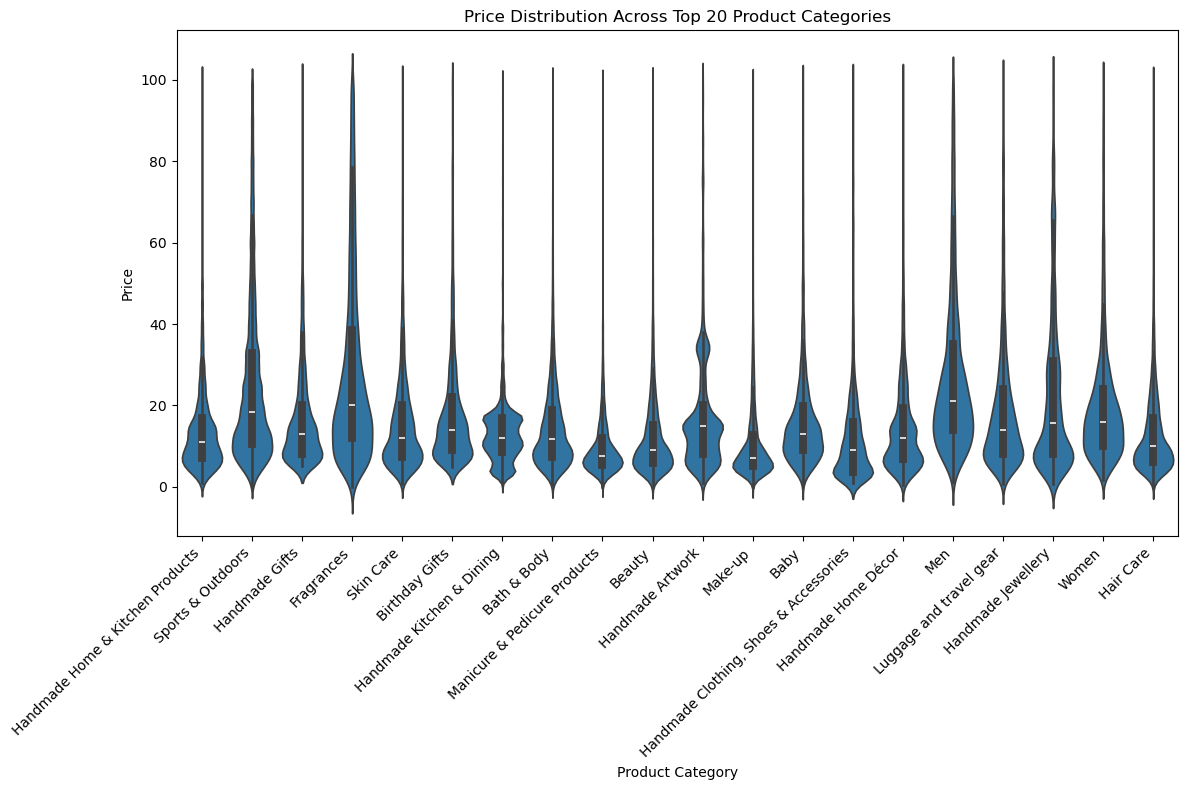

The product category with the highest median price is Desktop PCs with a median price of 74.0.


In [14]:

# Filter outliers using IQR previously calculated
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

# Determine the top 20 categories by count
top_categories = df_no_outliers['category'].value_counts().nlargest(20).index

# Filter the dataset for only the top categories
df_top_categories = df_no_outliers[df_no_outliers['category'].isin(top_categories)]

# Create a violin plot for the top categories
plt.figure(figsize=(12, 8))
sns.violinplot(x='category', y='price', data=df_top_categories, scale='width')
plt.xticks(rotation=45, ha='right')
plt.title('Price Distribution Across Top 20 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

# Identify the category with the highest median price among all categories
median_prices = df_no_outliers.groupby('category')['price'].median()
highest_median_price_category = median_prices.idxmax()
highest_median_price = median_prices.max()

print(f"The product category with the highest median price is {highest_median_price_category} with a median price of {highest_median_price}.")

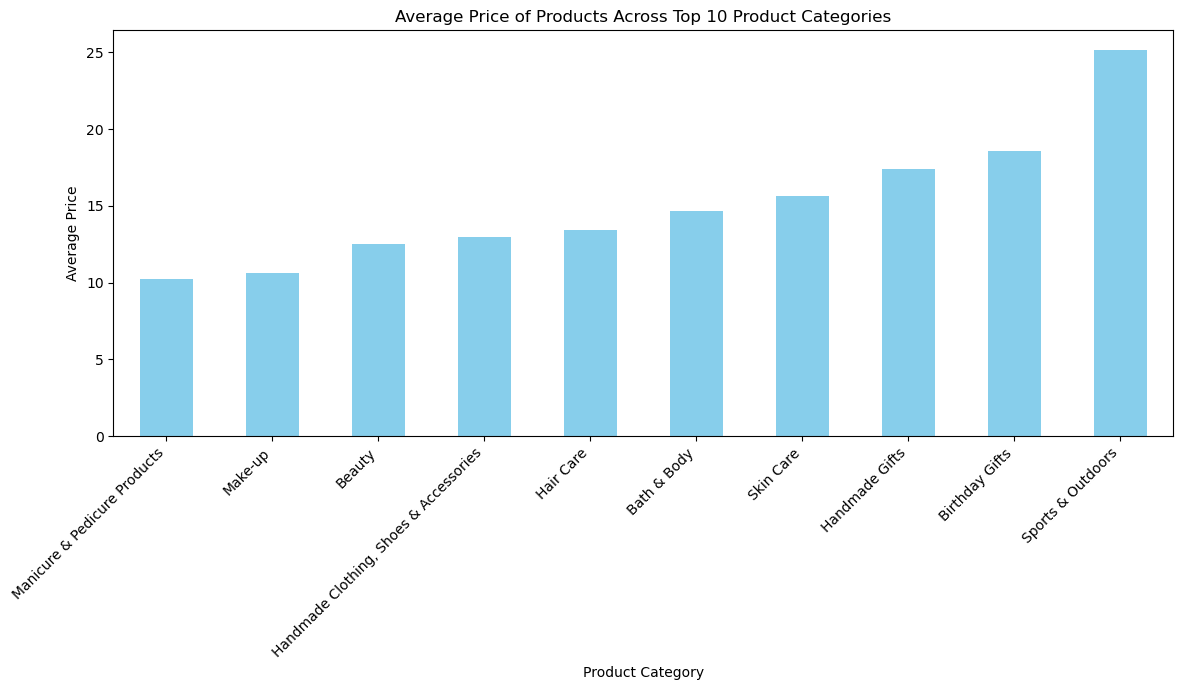

The product category with the highest average price overall is 'Motherboards' with an average price of 68.77.


In [15]:

# Remove outliers using IQR method
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

# Determine the top 10 categories by count
top_categories = df_no_outliers['category'].value_counts().nlargest(10).index

# Filter the DataFrame for only the top categories
df_top_categories = df_no_outliers[df_no_outliers['category'].isin(top_categories)]

# Calculate average prices for top categories
avg_prices_top_categories = df_top_categories.groupby('category')['price'].mean()

# Calculate the category with the highest average price overall
avg_prices_all_categories = df_no_outliers.groupby('category')['price'].mean()
highest_avg_price_category = avg_prices_all_categories.idxmax()
highest_avg_price = avg_prices_all_categories.max()

# Create a bar chart
plt.figure(figsize=(12, 7))
avg_prices_top_categories.sort_values().plot(kind='bar', color='skyblue')
plt.title('Average Price of Products Across Top 10 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Average Price')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(f"The product category with the highest average price overall is '{highest_avg_price_category}' with an average price of {highest_avg_price:.2f}.")

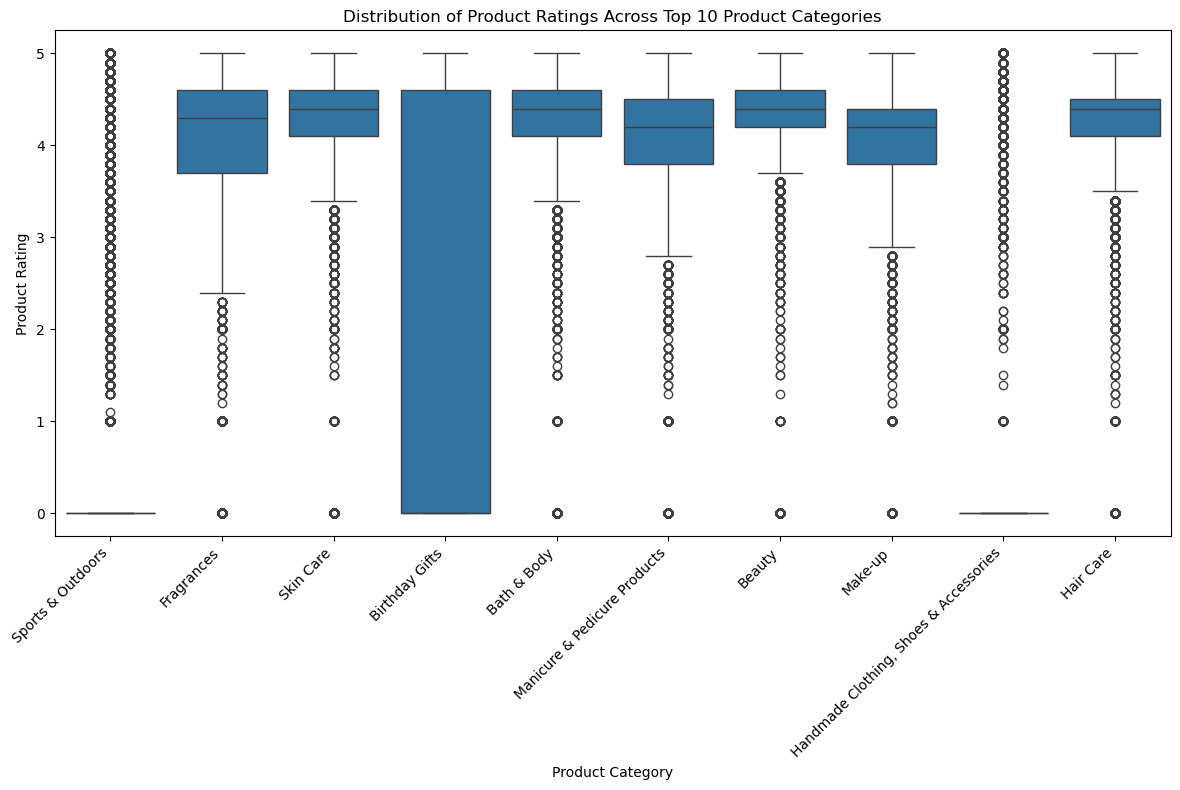

The category with the highest median rating is 'Computer Memory' with a median rating of 4.7.


In [17]:
# Filter the top 10 categories by count
top_categories = df['category'].value_counts().nlargest(10).index
df_top_categories = df[df['category'].isin(top_categories)]

# Plot box plots for the top categories
plt.figure(figsize=(12, 8))
sns.boxplot(x='category', y='stars', data=df_top_categories)
plt.xticks(rotation=45, ha='right')
plt.title('Distribution of Product Ratings Across Top 10 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Product Rating')
plt.tight_layout()
plt.show()

# Determine category with the highest median rating across all categories
median_ratings = df.groupby('category')['stars'].median()
highest_median_rating_category = median_ratings.idxmax()
highest_median_rating = median_ratings.max()

print(f"The category with the highest median rating is '{highest_median_rating_category}' with a median rating of {highest_median_rating}.")

In [18]:
# Check for and handle missing values
# If there are missing values, you can choose to drop them or fill them, but here we'll drop for simplicity
df_clean = df.dropna(subset=['price', 'stars'])

# Calculate the Pearson correlation coefficient
correlation_coefficient = df_clean['price'].corr(df_clean['stars'])

print(f"Correlation coefficient between price and rating: {correlation_coefficient:.4f}")

# Interpret the correlation
if correlation_coefficient > 0.5:
    interpretation = "There is a strong positive correlation between price and rating."
elif correlation_coefficient > 0.3:
    interpretation = "There is a moderate positive correlation between price and rating."
elif correlation_coefficient > 0:
    interpretation = "There is a weak positive correlation between price and rating."
elif correlation_coefficient < -0.5:
    interpretation = "There is a strong negative correlation between price and rating."
elif correlation_coefficient < -0.3:
    interpretation = "There is a moderate negative correlation between price and rating."
elif correlation_coefficient < 0:
    interpretation = "There is a weak negative correlation between price and rating."
else:
    interpretation = "There is little to no correlation between price and rating."

print(interpretation)

Correlation coefficient between price and rating: -0.1249
There is a weak negative correlation between price and rating.


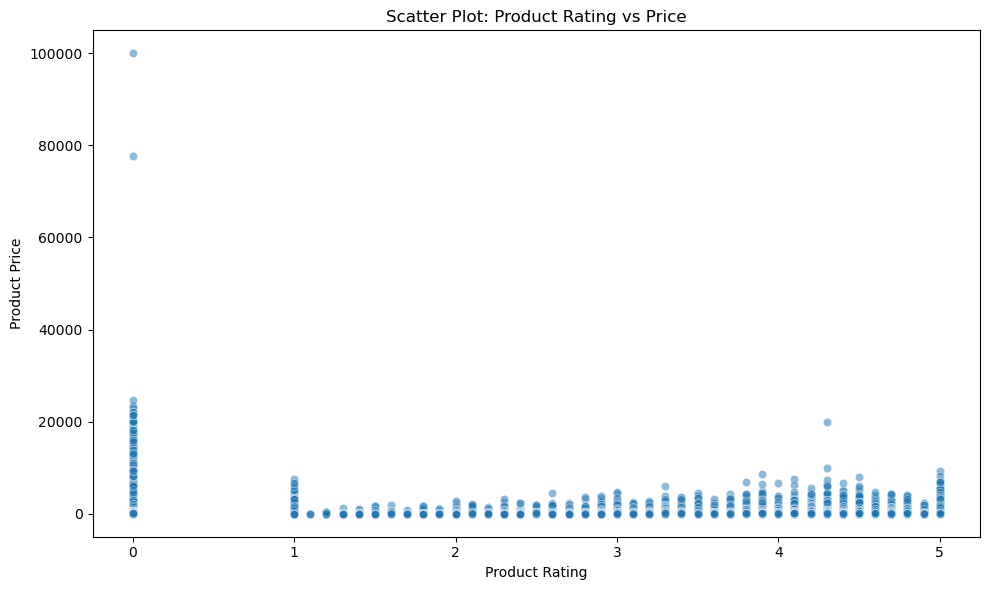

In [19]:
# Drop missing values for price and rating
df_clean = df.dropna(subset=['price', 'stars'])

# Create scatter plot for Price vs. Rating
plt.figure(figsize=(10, 6))
sns.scatterplot(x='stars', y='price', data=df_clean, alpha=0.5)
plt.title('Scatter Plot: Product Rating vs Price')
plt.xlabel('Product Rating')
plt.ylabel('Product Price')
plt.tight_layout()
plt.show()

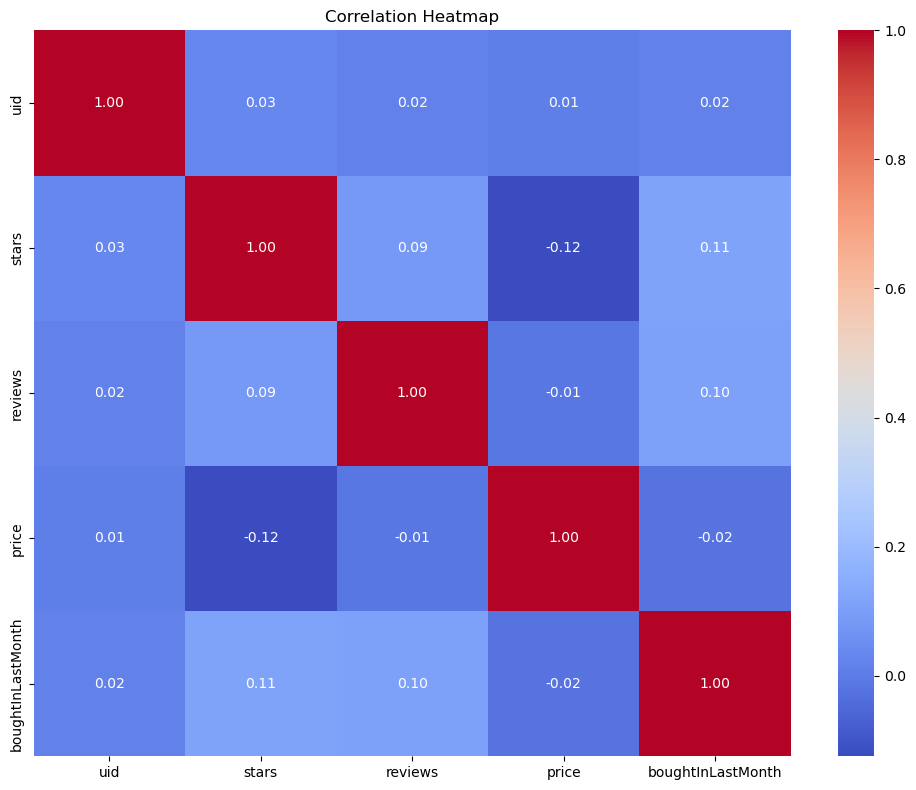

In [22]:
# Drop missing values for price and rating
df_clean = df.dropna(subset=['price', 'stars'])

# Select only numeric columns
numeric_df = df_clean.select_dtypes(include=['float64', 'int64'])

# Calculate correlation matrix using only numeric columns
correlation_matrix = numeric_df.corr()

# Use a heatmap to visualize correlations
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

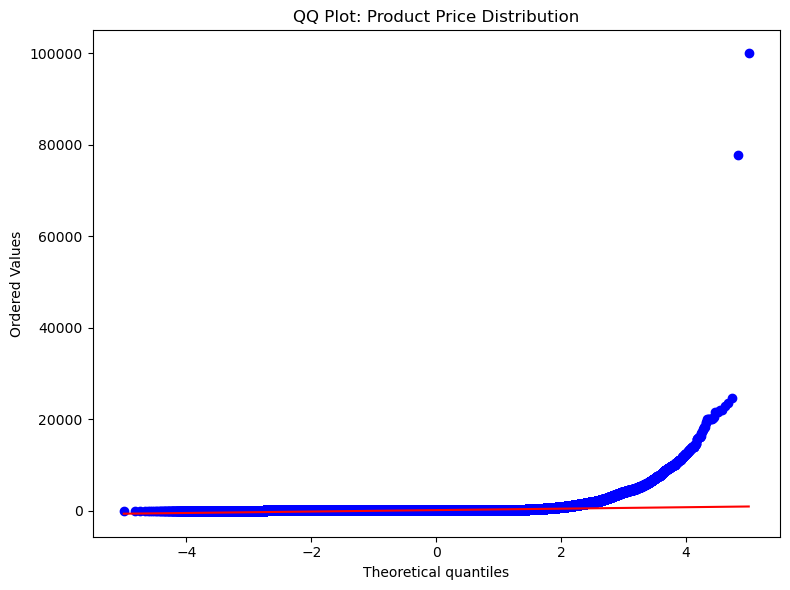

In [23]:
import scipy.stats as stats

# Plot QQ plot to check normality of product prices
plt.figure(figsize=(8, 6))
stats.probplot(df_clean['price'], dist="norm", plot=plt)
plt.title('QQ Plot: Product Price Distribution')
plt.tight_layout()
plt.show()